# Aula guiada · A cheia de janeiro de 2026 vista do espaço

**Workshop de Estudantes 1 · Projecto EYES TO EARTH (ETE) · 31 de Outubro de 2026**

## O problema

Em janeiro de 2026, o rio Incomáti teve a maior cheia dos últimos 20 anos: o caudal chegou a
**2 987 m³/s a 19 de janeiro** (num setembro normal leva menos de 1 m³/s).

> **Quantos hectares da planície de Marracuene ficaram debaixo de água? E onde?**

Vamos responder **juntos**, com duas imagens reais do satélite **Sentinel-2**: uma da época seca
(**2025-10-23**) e uma da cheia (**2026-01-24**, cinco dias depois do pico).

**A missão do dia:** no fim, cada par terá o seu próprio mapa de água, feito por si.

| Passo | O que fazemos | Ligação à teoria |
| --- | --- | --- |
| 1 | Abrir as imagens | Módulo 2: Landsat e Sentinel |
| 2 | Ver a seca e a cheia | Módulo 2 |
| 3 | Assinatura espectral de três píxeis | Módulo 3: como a água, a vegetação e o solo reflectem a luz |
| 4 | Calcular o NDWI e o MNDWI | Módulo 4 |
| 5 | Escolher o limiar | Módulo 4 |
| 6 | Contar a água em hectares | |
| 7 | Desenhar e guardar o mapa | |
| 8 | Confirmar com outras fontes | |
| 9 | Extra: 10 m contra 30 m | Módulo 2 |


| Sinal | Quer dizer |
| --- | --- |
| ▶️ | Corra a célula: clique nela e prima **Shift + Enter** |
| ✏️ | Edite: troque os `...` pela sua resposta e corra outra vez |
| ✍️ | Responda por escrito, na célula de texto logo abaixo (duplo clique para escrever) |
| ✅ | A célula verifica a sua resposta |

## As ferramentas (bibliotecas) que vamos usar

| Biblioteca | Para que serve | Comparação |
| --- | --- | --- |
| `numpy` (`np`) | Contas com tabelas de números. Uma imagem de satélite é uma tabela: cada píxel tem um número por banda | Uma calculadora que faz a mesma conta em 800 000 píxeis de uma vez |
| `matplotlib.pyplot` (`plt`) | Desenhar imagens, mapas, gráficos e histogramas | Lápis e papel |
| `os` e `glob` | Encontrar os ficheiros de dados no computador | Procurar uma pasta no armário |
| `ipywidgets` (opcional) | Uma barra deslizante para mudar o limiar com o rato | Um botão de volume |

Todas já vêm com o Google Colab: **não é preciso instalar nada**.

**Os dados.** A equipa ETE preparou os ficheiros `incomati_2026_seca.npz` e `incomati_2026_cheia.npz`
(cerca de 6 MB cada) a partir do Google Earth Engine. Cada um tem 5 bandas (azul, verde, vermelho, NIR e SWIR),
uma máscara de **nuvens** e uma máscara da **zona em estudo**: o distrito de Marracuene, sem o mar.
Assim ninguém precisa de descarregar imagens durante a aula.

## Passo 0 · Ligar as ferramentas ▶️

Esta célula chama as bibliotecas e cria quatro "receitas" (funções) que vamos usar:
`encontrar()` procura o ficheiro, `carregar()` abre-o, `cor_natural()` e `falsa_cor()` fazem imagens a cores.
Não é preciso perceber cada linha agora: leia os comentários depois de `#`.

In [1]:
# Célula 0 · ferramentas da aula: corra sem mudar nada ▶️
import os                          # os: trabalhar com pastas e ficheiros
import glob                        # glob: procurar ficheiros pelo nome
import numpy as np                 # numpy: contas com tabelas de números (uma imagem é uma tabela)
import matplotlib.pyplot as plt    # matplotlib: desenhar imagens e gráficos

BANDAS = ["azul", "verde", "vermelho", "nir", "swir"]


def encontrar(nome):
    """Procura um ficheiro de dados: ao lado do notebook, na pasta dados/, no Colab e no Google Drive."""
    for sitio in [nome, os.path.join("dados", nome), "/content/" + nome, "/content/dados/" + nome]:
        if os.path.exists(sitio):
            return sitio
    no_colab = os.getcwd().startswith("/content")
    bases = ["/content/drive/MyDrive"] if no_colab else [".", "..", "../.."]
    for base in bases:
        achados = glob.glob(os.path.join(base, "**", nome), recursive=True)
        if achados:
            return achados[0]
    try:
        from google.colab import files            # só existe no Google Colab
        print("Não encontrei", nome, "- escolha esse ficheiro no seu computador:")
        files.upload()
        if os.path.exists(nome):
            return nome
    except ImportError:
        pass
    raise FileNotFoundError(f"Não encontrei {nome}. Coloque-o na pasta 'dados' ao lado deste notebook.")


def carregar(nome):
    """Abre um ficheiro .npz e devolve um dicionário com as bandas em reflectância (0 a 1)."""
    z = np.load(encontrar(nome))
    img = {banda: z[banda] / 10000 for banda in BANDAS}   # guardámos números inteiros: dividir por 10 000
    img["nuvem"] = z["nuvem"]       # True onde há nuvem, sombra ou falta de dados
    img["zona"] = z["zona"]         # True dentro do distrito de Marracuene e fora do mar
    for chave in ["data", "satelite", "epoca", "data_pico"]:
        img[chave] = str(z[chave])
    for chave in ["caudal_m3s", "caudal_pico_m3s", "resolucao_m"]:
        img[chave] = float(z[chave])
    return img


def cor_natural(img, brilho=0.15):
    """Junta vermelho, verde e azul numa imagem a cores, como a veríamos de um avião."""
    rgb = np.dstack([img["vermelho"], img["verde"], img["azul"]])
    return np.clip(rgb / brilho, 0, 1)


def falsa_cor(img, brilho=0.35):
    """NIR no canal vermelho: a vegetação fica vermelha e a água fica quase preta."""
    rgb = np.dstack([img["nir"], img["vermelho"], img["verde"]])
    return np.clip(rgb / brilho, 0, 1)


print("Ferramentas prontas.")

Ferramentas prontas.


## Passo 1 · Abrir as imagens ▶️

`carregar()` devolve um **dicionário**: uma caixa com gavetas, cada uma com um nome.
A gaveta `seca["verde"]` tem a banda verde da imagem da seca: uma tabela de reflectâncias entre 0 e 1.

In [2]:
seca = carregar("incomati_2026_seca.npz")
cheia = carregar("incomati_2026_cheia.npz")

for img in [seca, cheia]:
    print(f"{img['epoca']:8s} {img['data']}  {img['satelite']}  caudal nesse dia: {img['caudal_m3s']:.0f} m³/s")

print("Pico do ano:", seca["caudal_pico_m3s"], "m³/s, a", seca["data_pico"])
print("Gavetas do dicionário:", list(seca.keys()))

seca     2025-10-23  Sentinel-2  caudal nesse dia: 5 m³/s
chuvosa  2026-01-24  Sentinel-2  caudal nesse dia: 1693 m³/s
Pico do ano: 2987.0 m³/s, a 2026-01-19
Gavetas do dicionário: ['azul', 'verde', 'vermelho', 'nir', 'swir', 'nuvem', 'zona', 'data', 'satelite', 'epoca', 'data_pico', 'caudal_m3s', 'caudal_pico_m3s', 'resolucao_m']


In [3]:
linhas, colunas = seca["verde"].shape
lado = seca["resolucao_m"]
print(f"Cada banda é uma tabela de {linhas} linhas x {colunas} colunas = {linhas * colunas} píxeis")
print(f"Cada píxel tem {lado:.0f} m x {lado:.0f} m = {lado * lado:.0f} m²")
print(f"A imagem cobre {colunas * lado / 1000:.0f} km x {linhas * lado / 1000:.0f} km")

# Um píxel do rio: linha 1034, coluna 232
print("Reflectância verde de um píxel do rio na seca:", seca["verde"][1034, 232].round(3))

Cada banda é uma tabela de 1110 linhas x 735 colunas = 815850 píxeis
Cada píxel tem 30 m x 30 m = 900 m²
A imagem cobre 22 km x 33 km
Reflectância verde de um píxel do rio na seca: 0.058


## Passo 2 · Ver o rio na seca e na cheia ▶️

A **cor natural** junta as bandas vermelho, verde e azul: é o que veríamos de um avião.
A linha amarela marca a **zona em estudo** (distrito de Marracuene, sem o mar).

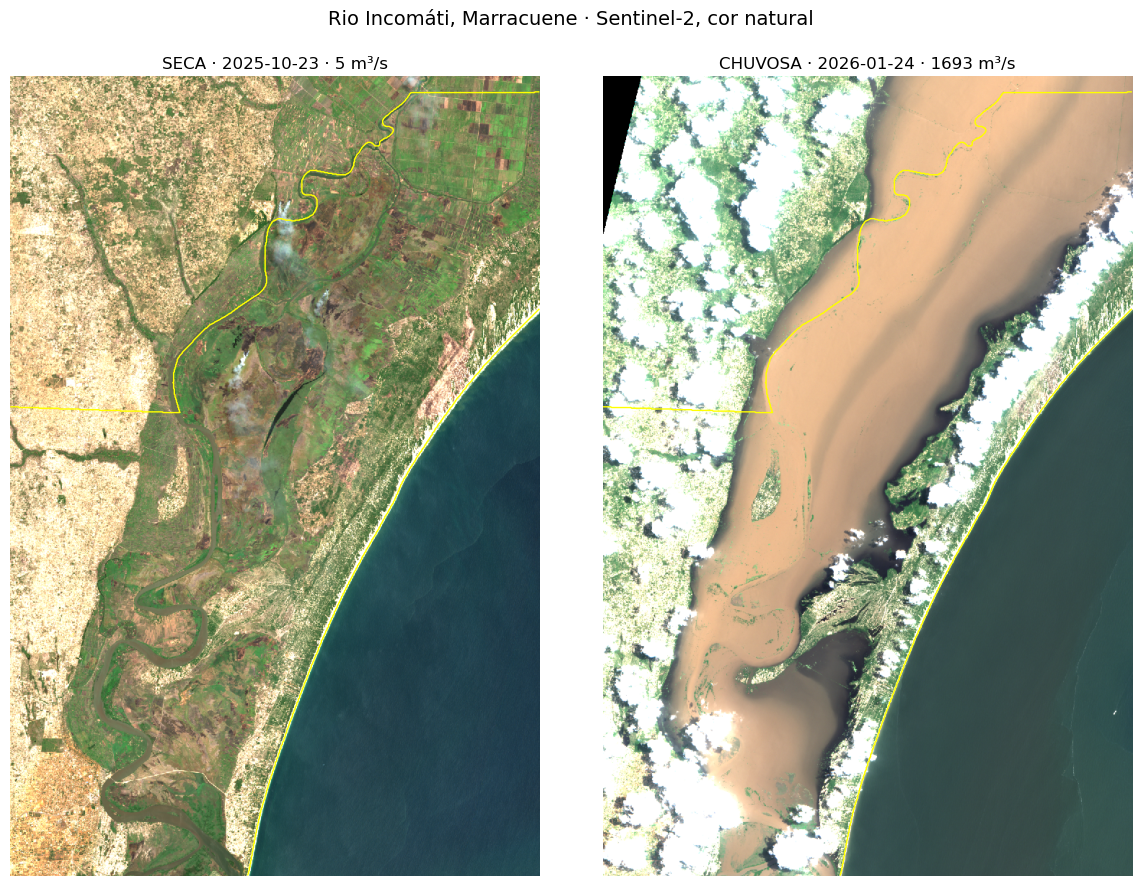

In [4]:
fig, eixos = plt.subplots(1, 2, figsize=(12, 9))
for eixo, img in zip(eixos, [seca, cheia]):
    eixo.imshow(cor_natural(img))
    eixo.contour(img["zona"], levels=[0.5], colors="yellow", linewidths=1)
    eixo.set_title(f"{img['epoca'].upper()} · {img['data']} · {img['caudal_m3s']:.0f} m³/s")
    eixo.axis("off")
plt.suptitle("Rio Incomáti, Marracuene · Sentinel-2, cor natural", fontsize=14)
plt.tight_layout(rect=(0, 0, 1, 0.96))       # deixa espaço para o título geral
plt.show()

✍️ **Pergunta aos pares:** o que mudou entre as duas imagens? Onde está a água da cheia?
De que cor é a água da cheia, e porquê? (Pista: Módulo 3, sedimentos e turbidez.)
E as manchas brancas na imagem da cheia?

*Resposta:*

### Falsa cor: ver o infravermelho (Módulo 3)

Pomos o **NIR no canal vermelho**. A vegetação reflecte muito NIR e fica **vermelha**;
a água absorve o NIR e fica **quase preta**.

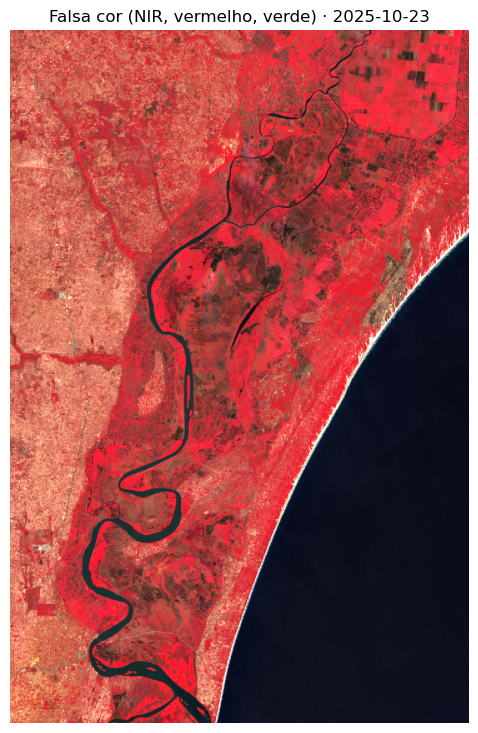

In [8]:
plt.figure(figsize=(6, 9))
plt.imshow(falsa_cor(seca))
plt.title(f"Falsa cor (NIR, vermelho, verde) · {seca['data']}")
plt.axis("off")
plt.show()

## Passo 3 · A assinatura espectral de três píxeis (Módulo 3) ▶️

Escolhemos três píxeis reais da imagem da seca, um de água, um de vegetação e um de solo nu,
e desenhamos a reflectância em cada banda.

Píxel            verde  vermelho       nir      swir
Água (rio)       0.058     0.061     0.030     0.008
Vegetação        0.052     0.025     0.517     0.161
Solo nu          0.146     0.180     0.234     0.397


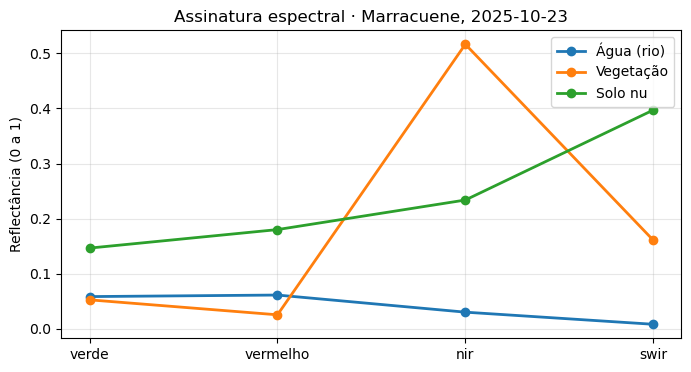

In [6]:
pixeis = {'Água (rio)': (1034, 232), 'Vegetação': (883, 135), 'Solo nu': (345, 636)}        # nome: (linha, coluna)
bandas = ["verde", "vermelho", "nir", "swir"]

print(f"{'Píxel':12s}" + "".join(f"{b:>10s}" for b in bandas))
plt.figure(figsize=(8, 4))
for nome, (l, c) in pixeis.items():
    valores = [seca[b][l, c] for b in bandas]
    print(f"{nome:12s}" + "".join(f"{v:10.3f}" for v in valores))
    plt.plot(bandas, valores, marker="o", linewidth=2, label=nome)
plt.ylabel("Reflectância (0 a 1)")
plt.title("Assinatura espectral · Marracuene, " + seca["data"])
plt.legend()
plt.grid(alpha=0.3)
plt.show()

✍️ **Compare com os píxeis misteriosos do Módulo 3:**

| Píxel | Verde | Vermelho | NIR | SWIR |
| --- | --- | --- | --- | --- |
| A | 0,06 | 0,04 | 0,02 | 0,01 |
| B | 0,10 | 0,05 | 0,45 | 0,20 |
| C | 0,15 | 0,20 | 0,28 | 0,35 |

Qual dos nossos três píxeis se parece com A? Com B? Com C?
Porque é que a água tem o verde maior do que o NIR e o SWIR?

*Resposta:*

## Passo 4 · Calcular o NDWI e o MNDWI (Módulo 4) ▶️

$$\text{NDWI} = \frac{\text{Verde} - \text{NIR}}{\text{Verde} + \text{NIR}} \qquad
\text{MNDWI} = \frac{\text{Verde} - \text{SWIR}}{\text{Verde} + \text{SWIR}}$$

O numpy faz a conta **para todos os píxeis de uma vez**. Se num píxel o denominador der 0, a divisão
não tem resultado: `np.errstate` evita avisos e esse píxel fica `nan`.

In [9]:
with np.errstate(divide="ignore", invalid="ignore"):      # sem avisos nas divisões por zero
    ndwi_seca   = (seca["verde"] - seca["nir"])   / (seca["verde"] + seca["nir"])
    ndwi_cheia  = (cheia["verde"] - cheia["nir"]) / (cheia["verde"] + cheia["nir"])
    mndwi_seca  = (seca["verde"] - seca["swir"])  / (seca["verde"] + seca["swir"])
    mndwi_cheia = (cheia["verde"] - cheia["swir"]) / (cheia["verde"] + cheia["swir"])

print("O MNDWI do píxel do rio na seca:", mndwi_seca[1034, 232].round(2))
print("O MNDWI do píxel de vegetação:  ", mndwi_seca[883, 135].round(2))

O MNDWI do píxel do rio na seca: 0.76
O MNDWI do píxel de vegetação:   -0.51


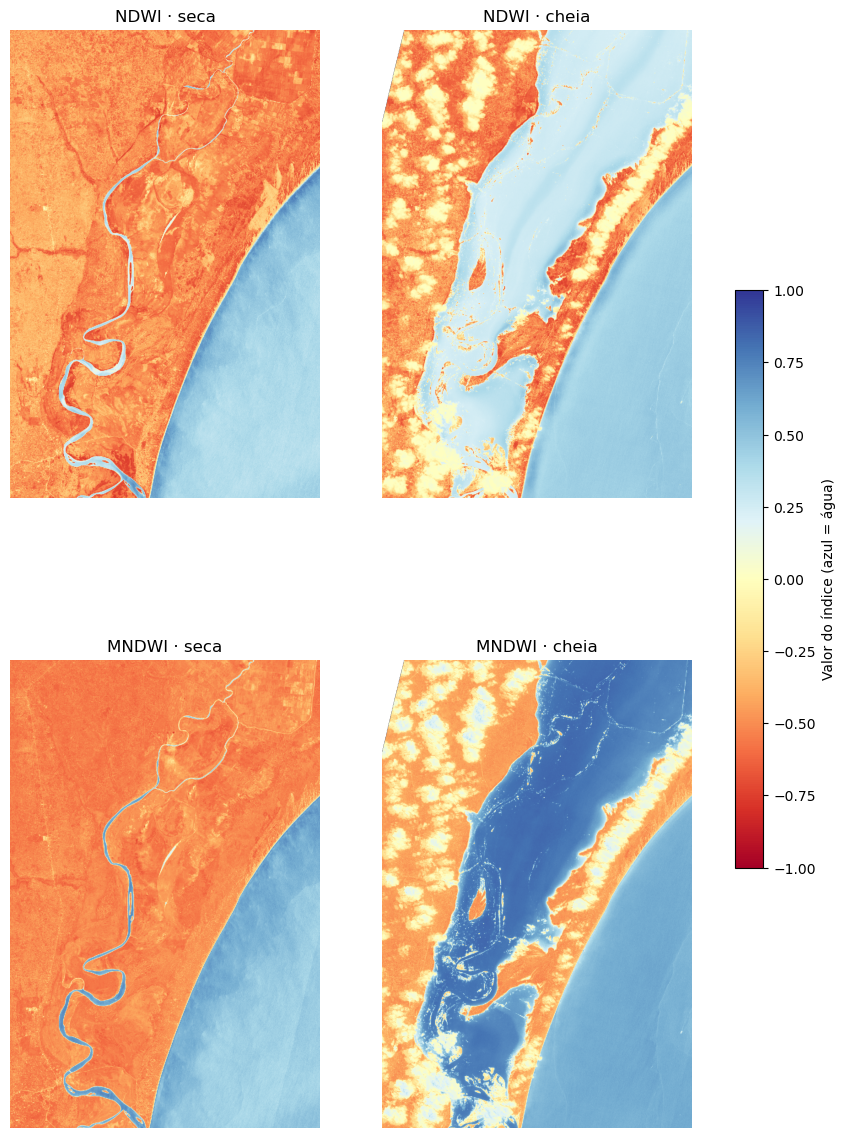

In [10]:
fig, eixos = plt.subplots(2, 2, figsize=(11, 15))
mapas = [(ndwi_seca, "NDWI · seca"), (ndwi_cheia, "NDWI · cheia"),
         (mndwi_seca, "MNDWI · seca"), (mndwi_cheia, "MNDWI · cheia")]
for eixo, (indice, titulo) in zip(eixos.ravel(), mapas):
    figura = eixo.imshow(indice, cmap="RdYlBu", vmin=-1, vmax=1)    # azul = valor alto = provável água
    eixo.set_title(titulo)
    eixo.axis("off")
fig.colorbar(figura, ax=eixos, shrink=0.5, label="Valor do índice (azul = água)")
plt.show()

✍️ **Pergunta:** onde aparece mais azul, na seca ou na cheia? O mar aparece azul nas duas: é por isso
que **não o contamos** (está fora da zona em estudo). As nuvens parecem água?

*Resposta:*

## Passo 5 · Escolher o limiar ▶️

Um píxel é água se o índice for **maior do que o limiar**. O 0 é só o ponto de partida.
O histograma mostra quantos píxeis da zona (sem nuvens) têm cada valor:
um monte grande de terra (valores negativos) e um monte de água (positivos).
**Um bom limiar fica no vale entre os dois.**

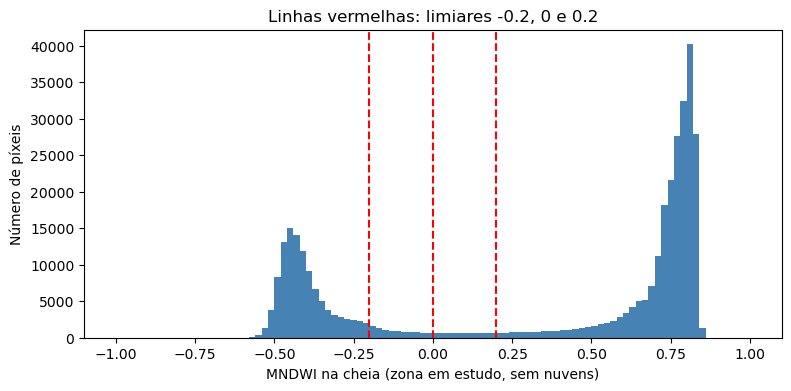

In [11]:
zona = seca["zona"]                                # a mesma zona nas duas imagens
vistos = zona & ~cheia["nuvem"]                    # na zona E sem nuvem
valores = mndwi_cheia[vistos]                      # só os píxeis que interessam

plt.figure(figsize=(9, 4))
plt.hist(valores, bins=100, range=(-1, 1), color="steelblue")
for limiar in [-0.2, 0.0, 0.2]:
    plt.axvline(limiar, color="red", linestyle="--")
plt.xlabel("MNDWI na cheia (zona em estudo, sem nuvens)")
plt.ylabel("Número de píxeis")
plt.title("Linhas vermelhas: limiares -0.2, 0 e 0.2")
plt.show()

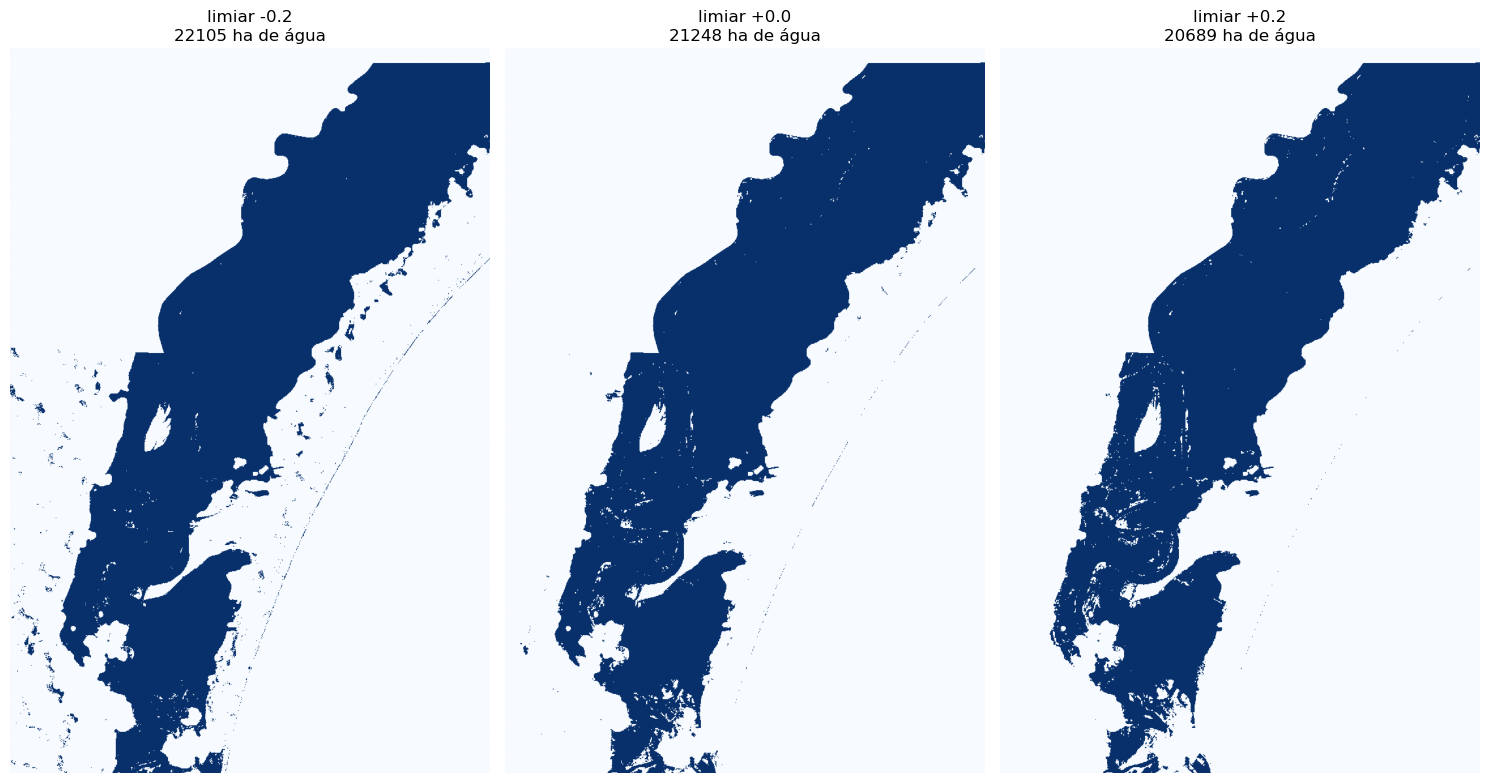

In [12]:
LIMIARES = [-0.2, 0.0, 0.2]        # ✏️ pode trocar e voltar a correr

fig, eixos = plt.subplots(1, len(LIMIARES), figsize=(5 * len(LIMIARES), 8))
for eixo, limiar in zip(eixos, LIMIARES):
    agua = (mndwi_cheia > limiar) & vistos
    eixo.imshow(agua, cmap="Blues")
    eixo.set_title(f"limiar {limiar:+.1f}\n{agua.sum() * 0.09:.0f} ha de água")
    eixo.axis("off")
plt.tight_layout()
plt.show()

**A analogia da peneira:** com buracos grandes (limiar baixo) passa "água" que não é água; com buracos
pequenos (limiar alto) perdemos a água pouco funda das margens. O analista escolhe e **justifica**.

Se tiver `ipywidgets` (o Colab tem), a célula seguinte cria uma barra para mudar o limiar com o rato.

In [13]:
try:
    from ipywidgets import FloatSlider, interact

    def ver_limiar(limiar=0.0):
        agua = (mndwi_cheia > limiar) & vistos
        plt.figure(figsize=(5, 7))
        plt.imshow(agua, cmap="Blues")
        plt.title(f"MNDWI > {limiar:+.2f} · {agua.sum() * 0.09:.0f} ha")
        plt.axis("off")
        plt.show()

    interact(ver_limiar, limiar=FloatSlider(min=-0.5, max=0.5, step=0.05, value=0.0))
except ImportError:
    print("Sem ipywidgets: use a célula anterior para testar limiares.")

interactive(children=(FloatSlider(value=0.0, description='limiar', max=0.5, min=-0.5, step=0.05), Output()), _…

## Passo 6 · Contar a água em hectares ▶️

Contamos só os píxeis que são **água E estão na zona E não têm nuvem** (`&` quer dizer "e", `~` quer dizer "não").
Cada píxel tem 30 m × 30 m = 900 m² = **0.09 hectares**.
**Água nova** = água na cheia que **não** era água na seca, contando só píxeis vistos nas duas datas.

In [14]:
LIMIAR = 0.0                                     # o limiar escolhido no Passo 5
area_pixel_ha = 30 * 30 / 10000                  # 0.09 ha

agua_seca  = (mndwi_seca > LIMIAR)  & zona & ~seca["nuvem"]
agua_cheia = (mndwi_cheia > LIMIAR) & zona & ~cheia["nuvem"]
valido = zona & ~seca["nuvem"] & ~cheia["nuvem"]                 # vistos nas duas datas
nova = (mndwi_cheia > LIMIAR) & ~(mndwi_seca > LIMIAR) & valido

ha_seca, ha_cheia, ha_nova = [m.sum() * area_pixel_ha for m in (agua_seca, agua_cheia, nova)]
nuvem_pct = 100 * cheia["nuvem"][zona].mean()                    # média de True/False = fracção

print(f"Zona em estudo: {zona.sum() * area_pixel_ha:.0f} ha")
print(f"Nuvens na zona, na cheia: {nuvem_pct:.1f} %")
print(f"Água na seca : {ha_seca:8.0f} ha")
print(f"Água na cheia: {ha_cheia:8.0f} ha  (pelo menos: as nuvens tapam parte)")
print(f"Água NOVA    : {ha_nova:8.0f} ha = {ha_nova / 100:.0f} km² = {ha_nova / 0.714:.0f} campos de futebol")

Zona em estudo: 39515 ha
Nuvens na zona, na cheia: 19.5 %
Água na seca :     1238 ha
Água na cheia:    21248 ha  (pelo menos: as nuvens tapam parte)
Água NOVA    :    20244 ha = 202 km² = 28353 campos de futebol


✍️ **Pergunta:** porque dizemos "pelo menos"? O que pode estar debaixo das nuvens?

*Resposta:*

> **Porque é tão importante a zona?** Se contássemos o mar como "água", teríamos milhares de hectares
> de "água" nas duas datas, e a cheia quase desaparecia nas contas. Foi o que aconteceu numa primeira
> versão desta aula: deu −26 ha de diferença entre a seca e a cheia.

## Passo 7 · O mapa final ▶️

Começamos com um mapa todo branco e pintamos por camadas: zona, água antes, água nova, nuvens.

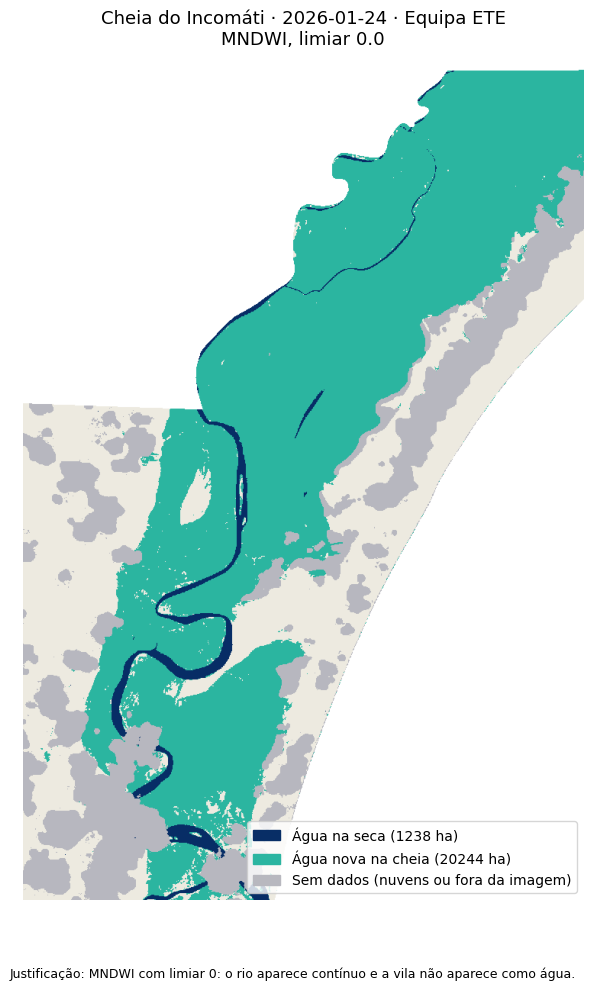

Mapa guardado: mapa_cheia_2026_Equipa_ETE.png


In [15]:
NOME_PAR = "Equipa ETE"          # ✏️ o nome do par
JUSTIFICACAO = "MNDWI com limiar 0: o rio aparece contínuo e a vila não aparece como água."  # ✏️

mapa = np.ones(zona.shape + (3,))                     # tudo branco (vermelho, verde, azul = 1)
mapa[zona] = [0.93, 0.92, 0.88]                       # zona em estudo: bege
mapa[agua_seca] = [0.03, 0.18, 0.40]                  # água antes da cheia: azul escuro
mapa[nova] = [0.17, 0.71, 0.63]                       # água nova: verde-água
mapa[zona & (seca["nuvem"] | cheia["nuvem"])] = [0.72, 0.72, 0.75]   # sem dados: cinzento

from matplotlib.patches import Patch
legenda = [Patch(color=[0.03, 0.18, 0.40], label=f"Água na seca ({ha_seca:.0f} ha)"),
           Patch(color=[0.17, 0.71, 0.63], label=f"Água nova na cheia ({ha_nova:.0f} ha)"),
           Patch(color=[0.72, 0.72, 0.75], label="Sem dados (nuvens ou fora da imagem)")]

plt.figure(figsize=(8, 11))
plt.imshow(mapa)
plt.legend(handles=legenda, loc="lower right", fontsize=10)
plt.title(f"Cheia do Incomáti · {cheia['data']} · {NOME_PAR}\nMNDWI, limiar {LIMIAR}", fontsize=13)
plt.figtext(0.5, 0.04, "Justificação: " + JUSTIFICACAO, ha="center", fontsize=9, wrap=True)
plt.axis("off")
ficheiro = "mapa_cheia_2026_" + NOME_PAR.replace(" ", "_") + ".png"
plt.savefig(ficheiro, dpi=150, bbox_inches="tight")
plt.show()
print("Mapa guardado:", ficheiro)

try:
    from google.colab import files       # no Colab, descarrega o mapa para o computador
    files.download(ficheiro)
except ImportError:
    pass

## Passo 8 · Confirmar com outras fontes

Um bom analista **confirma** o resultado com fontes independentes:

| Fonte | Como mede | Água nova da cheia de janeiro de 2026 |
| --- | --- | --- |
| Este notebook | Sentinel-2 (óptico), MNDWI > 0, 2026-01-24 | cerca de 202 km² (com 20% de nuvens) |
| Radar Sentinel-1 (projecto ETE) | Radar, vê através das nuvens, mês de janeiro | cerca de 214 km² (numa área um pouco maior) |
| Copernicus EMS (EMSR857) | Mapa oficial da cheia, feito por especialistas | usado pelo ETE para validar os modelos |

Os números são parecidos. As diferenças vêm das nuvens, da data de cada imagem e da área de cada mapa.

**Limitações honestas do nosso mapa:** as nuvens escondem parte da planície; a imagem é de 5 dias depois do
pico (a água já tinha começado a baixar); a 30 m perdemos canais estreitos; água debaixo de vegetação densa
pode não aparecer.

✍️ **O desafio do analista:** se o céu estivesse todo nublado durante a cheia, como faríamos o mapa?

*Resposta:*

## Passo 9 (extra) · 10 m contra 30 m (Módulo 2) ▶️

A mesma zona agrícola a norte da vila, 5 km × 5 km: à esquerda o **Sentinel-2A (10 m)**, à direita o
**Landsat 9 (30 m)**. São imagens reais, não simuladas.

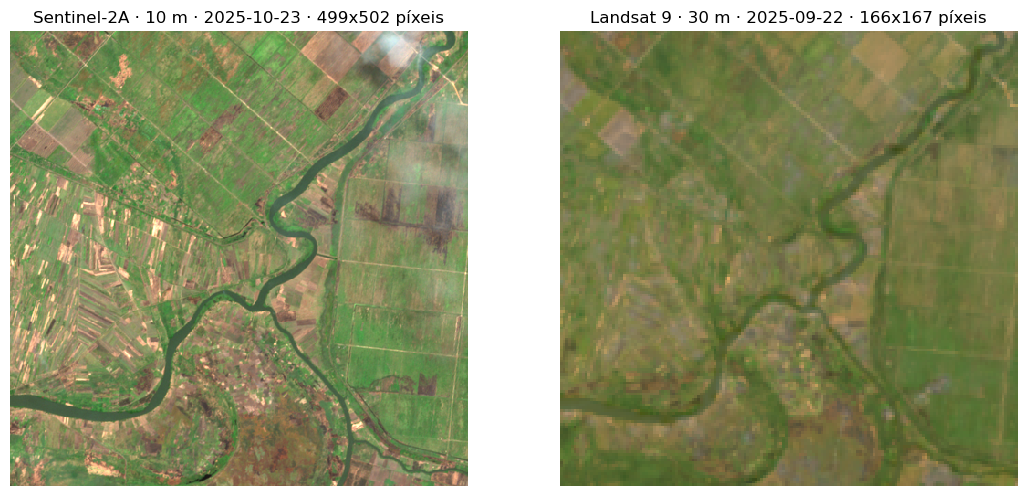

Píxeis a 10 m: 250498 · píxeis a 30 m: 27722
O Sentinel-2 tem 9 vezes mais píxeis na mesma zona


In [16]:
z = np.load(encontrar("zona_agricola_10m_e_30m.npz"))

def rgb(prefixo):
    return np.clip(np.dstack([z[prefixo + "_vermelho"], z[prefixo + "_verde"], z[prefixo + "_azul"]]) / 10000 / 0.15, 0, 1)

s2, ls = rgb("s2_10m"), rgb("landsat_30m")
fig, eixos = plt.subplots(1, 2, figsize=(13, 6.5))
eixos[0].imshow(s2, interpolation="nearest")
eixos[0].set_title(f"Sentinel-2A · 10 m · {str(z['data_s2'])} · {s2.shape[0]}x{s2.shape[1]} píxeis")
eixos[1].imshow(ls, interpolation="nearest")
eixos[1].set_title(f"Landsat 9 · 30 m · {str(z['data_landsat'])} · {ls.shape[0]}x{ls.shape[1]} píxeis")
for e in eixos:
    e.axis("off")
plt.show()
print(f"Píxeis a 10 m: {s2.shape[0] * s2.shape[1]} · píxeis a 30 m: {ls.shape[0] * ls.shape[1]}")
print(f"O Sentinel-2 tem {s2.shape[0] * s2.shape[1] / (ls.shape[0] * ls.shape[1]):.0f} vezes mais píxeis na mesma zona")

✍️ **Perguntas:** quantos talhões consegue contar em cada imagem? Para mapear a cheia de **janeiro de 2013**,
que satélite usaríamos? (Pista: o Sentinel-2 começou em 2015 e o Landsat 8 só ficou operacional em abril de 2013.)

*Resposta:*

## O que aprendemos

1. Uma imagem de satélite é uma **tabela de números**, uma por banda.
2. A água reflecte mais **verde** do que **NIR** e **SWIR**: é isso que os índices NDWI e MNDWI aproveitam.
3. O **limiar** decide o que é água; escolhe-se olhando para o histograma e para o mapa, e justifica-se.
4. Contamos **só o que vemos**: fora do mar, fora das nuvens. Com nuvens, o resultado é um **mínimo**.
5. Um resultado confirma-se com **outras fontes** (radar, mapas oficiais).

**Agora é a vez de cada par:** abra a pasta `3_exercicios`, escolha o ano que lhe foi atribuído e faça o mesmo.

## Se aparecer um erro

Leia **a última linha** da mensagem vermelha. Quase sempre é um destes:

| Última linha do erro | O que quer dizer | O que fazer |
| --- | --- | --- |
| `NameError: name 'np' is not defined` | Saltou a Célula 0 | Corra a Célula 0 e depois as outras, por ordem |
| `NameError: name 'seca' is not defined` | Saltou a célula que carrega os dados | Corra as células por ordem, de cima para baixo |
| `AssertionError: ✏️ Volte à célula anterior...` | Ficaram `...` por preencher | Complete a célula ✏️ anterior |
| `FileNotFoundError: Não encontrei ...npz` | O ficheiro de dados não está ao lado do notebook | Ponha a pasta `dados` ao lado do notebook, ou carregue o ficheiro quando o Colab pedir |
| `SyntaxError` | Falta um parêntese, uma aspa ou uma vírgula | Compare a sua linha com o exemplo logo acima |
| `IndentationError` | Os espaços no início da linha estão errados | Use 4 espaços dentro de `if`, `for` e `def` |

Se nada resultar: menu **Ambiente de execução → Reiniciar e executar tudo** (Colab) ou **Kernel → Restart & Run All** (Jupyter).